## 1. Concept and motivation {#concept-and-motivation}

**Ball Carrier Open Space (BCOS)** is the space a player in possession can navigate without interference from an opponent. Bandara et al. [@bandara2025bcos] define it as the unoccupied area surrounding the ball carrier and investigate its spatial and temporal variation and association with match results.

PRESS extends this concept by assigning each candidate destination an accessibility probability: the probability that the carrier reaches it before being intercepted. Each destination defines a hypothetical straight-line route along which the carrier moves while exposed to opposing players. Arrival at the destination and interception are competing terminal events.

To quantify the probability of arrival before interception, the model builds on the probabilistic representation of player movement introduced by Spearman [@spearman2017; @spearman2018beyond]. In the [ball-drive risk model](../../01_ball_drive_risk/01_ball_drive_risk.ipynb), the carrier follows a deterministic trajectory while the movement of defenders is uncertain. BCOS represents the movement of both the carrier and the defenders through probabilistic arrival-time distributions. The resulting accessibility surface describes the spatial organization and extent of the carrier's movement opportunities.

The formulation developed below is the extended transport-with-killing model, including interception during waiting at the origin. The existing pretrained action-selection and residual-risk classifiers and their reported benchmarks use a preliminary effective-hazard formulation, which remains available in the package. Retraining and held-out evaluation with the extended formulation are [planned](../../../roadmap.qmd). Differences between the formulations do not establish a predictive improvement.

## 2. Mathematical formulation {#mathematical-formulation}

BCOS combines probabilistic player movement with transport subject to killing and boundary absorption. The forward equation for diffusion with killing and boundary absorption studied by Holcman, Marchewka and Schuss [@holcman2005] motivates the use of a probability-density equation with an interior sink and an absorbing boundary. In PRESS, the spatial dynamics are described by deterministic transport, killing represents interception of the carrier by a defender, and boundary absorption represents successful arrival at the destination.

Treating arrival and interception as competing risks provides a common mathematical setting for BCOS, pass risk and ball-drive risk. It also allows the interception probability along each route to be decomposed into contributions from individual defenders. The [appendix](../../../appendix/bcos-transport-with-killing.qmd) gives the full derivation, movement kinematics and solution checks.

### Probabilistic player movement

Let $x_{\mathrm{bc}}(0)$ denote the observed position of the carrier. For a candidate destination $z$, the straight-line route is

$$x(\ell;z)=x_{\mathrm{bc}}(0)+\frac{\ell}{L_z}(z-x_{\mathrm{bc}}(0)),\qquad 0\leq\ell\leq L_z,\qquad L_z=\|z-x_{\mathrm{bc}}(0)\|.$$

For each player $j$, the nominal **time to intercept (TTI)** at location $x$ is

$$\tau_j(x)=t_{\mathrm{turn},j}(x)+t_{\mathrm{move},j}(x),$$

where $t_{\mathrm{turn},j}(x)$ is the turning delay required to reorient towards $x$, and $t_{\mathrm{move},j}(x)$ is the travel time under the acceleration-limited movement model of PRESS. Both depend on the player's observed position and velocity. The movement model uses separate maximal speeds and accelerations for the carrier and defenders (see [Motion parameters](#motion-parameters)). For a defender, $\tau_j(x)$ represents the nominal time required to reach a potential interception location; for the carrier, $\tau_{\mathrm{bc}}(x)$ represents the nominal time required to reach that location along the candidate route.

Following Spearman [@spearman2017; @spearman2018beyond], uncertainty in these arrival times is represented by a logistic cumulative distribution,

$$F_j(x,t)=\left[1+\exp\{-\kappa[t-\tau_j(x)]\}\right]^{-1},\qquad \kappa=\frac{\pi}{\sqrt{3}\,s},$$

where $s$ is the standard deviation of arrival-time uncertainty. In the production model, $s$ is inherited from the ball-drive risk model fitted on the ten matches. The associated arrival hazard (arrival intensity), conditional on not having reached $x$ by time $t$, is

$$\lambda_j^{\mathrm{arr}}(t\mid x)=\frac{\partial_t F_j(x,t)}{1-F_j(x,t)}=\kappa F_j(x,t).$$

### Carrier transport and initial conditioning

Along a route, the carrier's turning angle is fixed, so its turning delay $t_{\mathrm{turn}}$ is constant; write $t_{\mathrm{move}}(\ell)$ for its travel time over the distance $\ell$. The uncertainty in the carrier's movement is a single random delay, common to all points of the route. A carrier whose delay has not yet elapsed is still at the observed origin, waiting to start. Negative transport coordinates represent waiting at the observed origin, including the turning phase. The nominal time is extended to these coordinates by

$$\tau_{\mathrm{bc}}(\ell)=t_{\mathrm{turn}}+\begin{cases}-t_{\mathrm{move}}(-\ell),&\ell<0,\\t_{\mathrm{move}}(\ell),&\ell\ge0.\end{cases}$$

The extension is strictly increasing and tends to $-\infty$ as $\ell\to-\infty$. It preserves the positive-route kinematics and introduces no new parameter. The physical location is therefore

$$x(\ell;z)=x_{\mathrm{bc}}(0)+\frac{\max(\ell,0)}{L_z}(z-x_{\mathrm{bc}}(0)),\qquad \ell\le L_z.$$

The transport velocity is $\nu_{\mathrm{bc}}=1/\tau_{\mathrm{bc}}'$ almost everywhere. The reference function $F_{\mathrm{bc}}(\ell,t)$ is the logistic distribution above evaluated with the extended $\tau_{\mathrm{bc}}(\ell)$; its spatial density and current are

$$p_0(\ell,t)=-\partial_\ell F_{\mathrm{bc}}(\ell,t),\qquad \nu_{\mathrm{bc}}(\ell)p_0(\ell,t)=\partial_tF_{\mathrm{bc}}(\ell,t).$$

The reference density satisfies $\partial_tp_0+\partial_\ell(\nu_{\mathrm{bc}}p_0)=0$. At time zero, we condition only on the carrier not having reached the destination:

$$Z_z=1-F_{\mathrm{bc}}(L_z,0),\qquad p_k(\ell,0)=p_0(\ell,0)/Z_z,\quad \ell<L_z.$$

All mass preceding entry is retained on the negative half-line. Without a turning delay, the unconditioned reference median is zero; a turning delay shifts it to a negative latent coordinate, which still represents the observed origin. For small arrival-time dispersion, the initial physical position concentrates near that origin.

### Transport with interception

The reference transport describes carrier movement in the absence of interception. To introduce defensive opposition, BCOS follows the approach used in pitch control, where player arrival is evaluated at successive points along the ball trajectory. Here, each point along the carrier's route represents a potential interception location. Interception occurs when a defender reaches the location occupied by the carrier while the carrier is still in possession. PRESS specifies the interception intensity of defender $i$ at that location as its arrival intensity. The total killing intensity is

$$k_z(\ell,t)=\sum_{i\in\mathrm{opp}} k_{z,i}(\ell,t),\qquad k_{z,i}(\ell,t)=\lambda_i^{\mathrm{arr}}(t\mid x(\ell;z)).$$

Introducing this killing intensity into the transport equation gives the density of the carrier still on the route without interception:

$$\boxed{\partial_t p_k+\partial_\ell(\nu_{\mathrm{bc}}p_k)=-k_zp_k.}$$

The equation holds on $(-\infty,L_z)$ with the conditioned initial density above. For negative coordinates, killing is evaluated at the observed origin, allowing interception before movement along the route begins. The destination is an absorbing outflow boundary and the only finite boundary of the domain.

The solution by characteristics is

$$p_k(\ell,t)=\frac{p_0(\ell,t)}{Z_z}\exp\!\left[-\int_0^t k_z(X_\xi,\xi)\,d\xi\right],\qquad X_\xi=\tau_{\mathrm{bc}}^{-1}(\tau_{\mathrm{bc}}(\ell)-t+\xi).$$

Every backward characteristic reaches time zero. The [appendix](../../../appendix/bcos-transport-with-killing.qmd) derives the solution in the transport-time coordinate, including the case of zero initial speed.

### Competing events and accessibility

The transport equation describes two ways in which probability mass leaves the route: arrival at the destination and interception. The corresponding destination flux and the interception flux attributable to defender $i$ are

$$j_L(t)=\nu_{\mathrm{bc}}(L_z)p_k(L_z^-,t),\qquad j_i(t)=\int_{-\infty}^{L_z}k_{z,i}(\ell,t)p_k(\ell,t)\,d\ell.$$

The probability of remaining at risk is the total surviving mass:

$$S(t)=\int_{-\infty}^{L_z}p_k(\ell,t)\,d\ell.$$

The corresponding cause-specific hazards are

$$h_L(t)=\frac{j_L(t)}{S(t)},\qquad h_i(t)=\frac{j_i(t)}{S(t)},\qquad h_k(t)=\sum_i h_i(t).$$

The accessibility probability is the cumulative incidence of reaching the destination before interception,

$$\boxed{p_{\mathrm{bc}}(z)=\int_0^\infty S(t)h_L(t)\,dt=\int_0^\infty j_L(t)\,dt.}$$

Similarly, $P_i(z)=\int_0^\infty S(t)h_i(t)\,dt$ is the probability that defender $i$ intercepts the carrier before any other terminal event. Since $p_{\mathrm{bc}}(z)+\sum_iP_i(z)=1$, the competing-risks formulation provides a route-specific attribution of defensive threat in addition to the overall accessibility probability. Without opponents, $p_{\mathrm{bc}}(z)=1$.

### Accessibility surface and BCOS area

Repeating this route-specific calculation across destinations produces the accessibility surface $z\mapsto p_{\mathrm{bc}}(z)$. Let $\mathcal D_R$ be the pitch-clipped region within a maximal radius $R$ of the carrier ($R=40$ m in PRESS). The spatial integral of the surface over this region defines the **probability-weighted accessible area**,

$$\boxed{A_{\mathrm{BCOS}}(s_0)=\int_{\mathcal D_R}p_{\mathrm{bc}}(z)\,dz\qquad [\mathrm{m}^2],}$$

where $s_0$ is the observed tracking state. The surface retains the spatial organization of movement opportunities, while the area summarizes their extent.

BCOS is implemented as `PRESS.spatial_features.BCOS`. The [ball-drive risk model](../../01_ball_drive_risk/01_ball_drive_risk.ipynb) quantifies loss risk over a fixed one-second horizon, with a loss intensity estimated from observed possession losses. BCOS instead evaluates the probability of avoiding interception along routes with destination-dependent durations that can exceed one second, and integrates these probabilities over the surrounding space. By characterizing the carrier's movement opportunities beyond the immediate action, the BCOS area complements ball-drive risk and is one of the main features used in the action-selection and residual-risk models of PRESS. It informs both the choice between carrying and passing the ball and the residual risk of losing possession following a successful action.

The defender-specific incidences above provide a mathematical decomposition of accessibility; the [example](#example-accessibility-on-a-real-tracking-frame) reports the accessibility surface and area.

## 3. Motion parameters {#motion-parameters}

The carrier and defenders have separate speed limits: $v_{\max,\mathrm{bc}}=6.6$ m/s and $v_{\max,\mathrm{def}}=7$ m/s. Both use linear and turning accelerations of $7$ m/s$^2$. These effective movement parameters are motivated by the literature and assessed against the tracking distribution, as summarized below.

| Parameter | Literature rationale | Tracking consistency check |
|---|---|---|
| Defender speed $v_{\max,\mathrm{def}}=7$ m/s | Approximately the 25.1 km/h sprint threshold in Bradley et al. [@bradley2009running], as in ball-drive risk. | Defensive-engagement event frames with speed $>2$ m/s: Q95 = **7.050 m/s**. |
| Carrier speed $v_{\max,\mathrm{bc}}=6.6$ m/s | Benhassen et al. [@benhassen2026dribbling] report an approximately 6% reduction in theoretical maximal velocity during dribbling. Applying this indicative reduction to 7 m/s gives 6.58 m/s, rounded to 6.6. Carling [@carling2010ballrunning] reports mean peak match speeds with the ball of about 6.86 m/s, supporting the broad scale. | In engagement frames where both carrier and defender move above 2 m/s, their Q95 values are **6.778** and **7.174 m/s**, respectively: the carrier value is **5.52% lower**. |
| Defender linear acceleration $a_{\mathrm{def}}=7$ m/s$^2$ | The effective acceleration used by Spearman's movement model [@spearman2018beyond], also used in ball-drive risk. | Defender acceleration peaks per engagement, above 3 m/s$^2$: Q99 = **6.966 m/s$^2$**. |
| Carrier linear acceleration $a_{\mathrm{bc}}=7$ m/s$^2$ | Extending the same arrival-model acceleration scale to the carrier is a modelling assumption, since the cited reduction refers to speed. | Carrier acceleration peaks per engagement give Q99 = **6.682 m/s$^2$** after a threshold of 3 m/s$^2$, and Q98 = **6.953 m/s$^2$** after 4 m/s$^2$. These support a rounded upper scale near 7 m/s$^2$. |
| Turning accelerations $a_{\mathrm{turn,bc}}=a_{\mathrm{turn,def}}=7$ m/s$^2$ | The heading-dependent turning delay follows Pleuler [@pleuler2020handbook]. PRESS sets its scale equal to the corresponding linear-acceleration parameter. | Equality with linear acceleration is a modelling convention; the turning scales are not separately identified by these quantiles. |

The carrier speed limit follows the approximate reduction in theoretical maximal velocity reported in the dribbling study and lies below the carrier's tracking Q95. The tracking quantiles serve as descriptive consistency checks of the chosen limits. The carrier and defender speed comparison uses the same frames, with both players moving; the speed filter removes stationary and walking observations. Acceleration checks use event peaks without a speed filter, retaining acceleration from low speed or rest. The thresholds and quantiles were chosen for exploratory checks.

The [kinematic conventions](../../../docs/kinematic-parameter-conventions.md) give the sampling definitions and sensitivity checks. The model takes observed positions and velocities as inputs. Arrival-time dispersion $s$ is inherited from the fitted ball-drive model, as described above.


## 4. Example: accessibility on a real tracking frame {#example-accessibility-on-a-real-tracking-frame}

We illustrate BCOS using a frame from Brisbane FC–Perth Glory, played on 21 December 2024 (match 1925299) [@skillcorner-opendata]. At 06:19 (frame 3800), Brisbane's F. Bérenguer has the ball close to the touchline. This checkpoint provides a clear view of the midfield configuration.

The figure shows the accessibility surface $p_{\mathrm{bc}}(z)$ computed from this frame with the extended transport formulation, including interception during waiting at the origin, for destinations within $R=40$ m of the carrier. The colour of each point is the probability that Bérenguer reaches it before any Perth player intercepts him, from 0 (dark) to 1 (light yellow). Blue dots are Brisbane players, red dots Perth players and the white dot is the ball; the short segments are player velocities. The green part of the pitch lies beyond the 40 m region of the calculation.

The highest accessibility probabilities occur in a compact region around the carrier, with accessible space extending mainly to his upper right along the touchline, away from nearby Perth players. Towards the centre of the pitch, where several Perth players are positioned, accessibility decreases rapidly. The integral of the surface, the probability-weighted accessible area, is 613.67 m², which is much smaller than the area of the 40 m region because most destinations have a low probability of being reached.





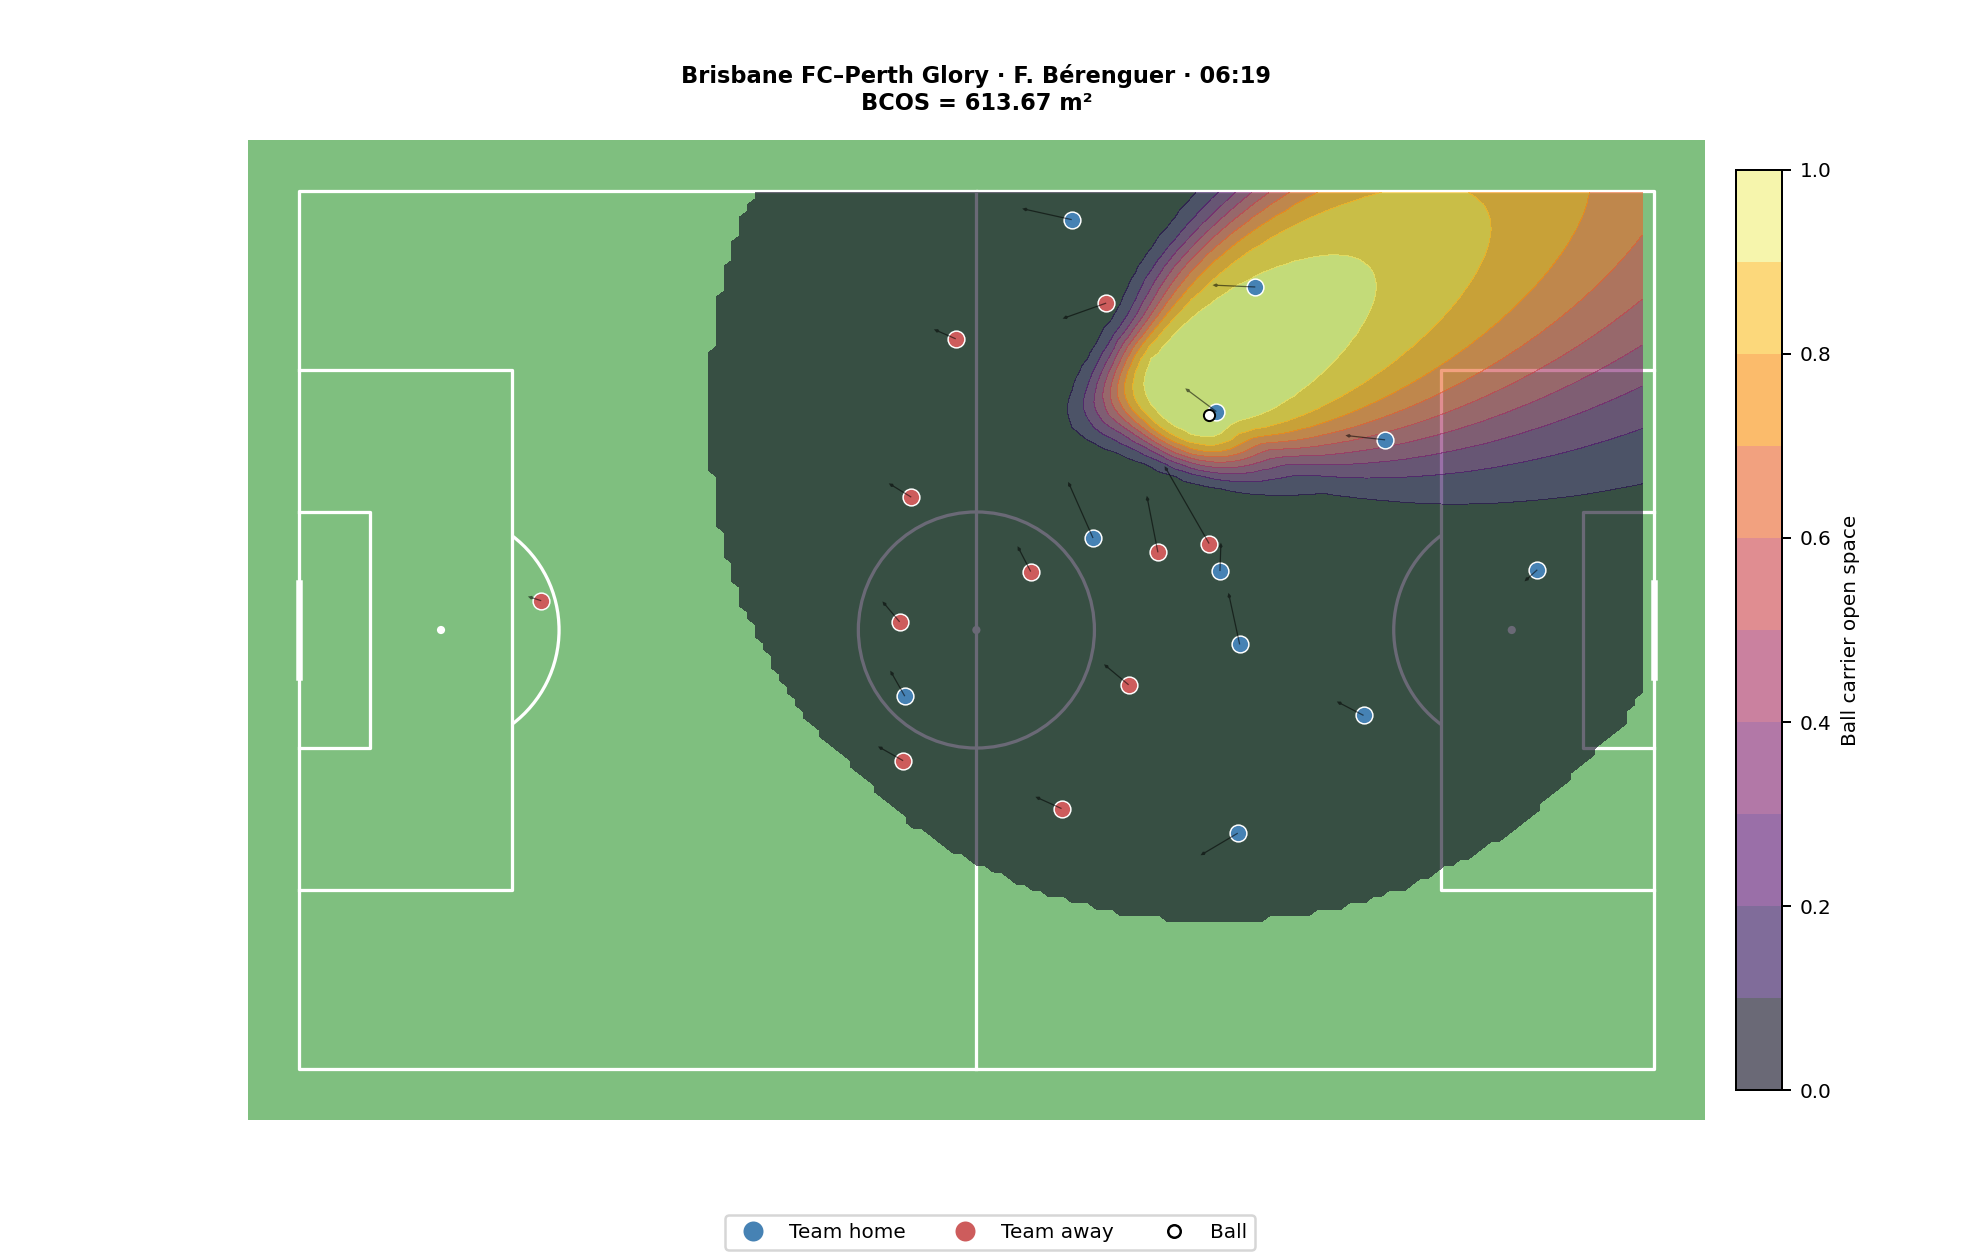

In [6]:
from pathlib import Path
from IPython.display import Image, display

# Transport formulation with interception during waiting at the origin.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "_quarto.yml").is_file())
display(Image(filename=str(root / "figures/vignette_10_bcos_transport.png")))


## 5. Spatiotemporal statistics for one match {#spatiotemporal-statistics-for-one-match}

Beyond the analysis of individual tracking frames, BCOS can be used to describe how accessible space varies with the carrier's position and over the course of a match. We examine these patterns in the same Brisbane FC–Perth Glory game using BCOS areas at the action-choice checkpoints: the canonical outfield, no-shot decision states, each with its original production value. The sample contains 1,928 checkpoints from 931 individual possessions, 1,238 checkpoints from 592 possessions for Brisbane and 690 from 339 for Perth.

As with the existing classifier benchmarks, these descriptive summaries use the preliminary effective-hazard formulation and have not been recomputed with the extended transport model.

### Spatial distribution by carrier position

To compare the spatial distributions, both teams are oriented to attack right, including after halftime. BCOS is computed on a one-metre destination grid, while the resulting areas are summarized on a 10 × 6 grid according to the carrier's position. For team $a$ and carrier-origin cell $g$, the colour is the mean BCOS area of the checkpoints whose carrier occupies that cell,

$$
\bar A_{a,g}=\frac{1}{n_{a,g}}\sum_{j:\,a_j=a,\,x_{\mathrm{bc},j}\in g}A_{\mathrm{BCOS}}(s_j).
$$

Both teams share one colour scale, and the labels give the number of distinct individual possessions in each cell.

![Mean BCOS by carrier-origin cell, on a 10 × 6 grid. Labels count distinct individual possessions.](../../../figures/bcos_match_spatial.png)

Because touchlines and goal lines constrain the available space differently across the pitch, we compare the teams within each third, where carriers face comparable spatial constraints. For both teams BCOS decreases from the defensive to the attacking third: 548.31, 365.72 and 81.64 m² for Brisbane, and 277.33, 260.13 and 68.23 m² for Perth. The advantage of Brisbane is largest in the defensive third (270.98 m² more than Perth), is reduced in the central third (105.59 m²) and almost vanishes in the attacking third (13.41 m²). In the defensive third, BCOS reflects the pressure applied during build-up. In this match, the difference suggests that Brisbane's carriers had more space to build from the back, while Perth stayed more compact behind.

### Temporal variation

To examine how these spatial differences develop over the match, we compare BCOS within each carrier-origin third between the two halves.

![Observed BCOS checkpoints and centred five-minute means, split by carrier-origin third and half.](../../../figures/bcos_match_temporal.png)

In the defensive third, Brisbane's mean rises from 493.02 m² in the first half to 592.92 m² in the second, whereas Perth's falls from 312.02 to 212.03 m². The gap between the teams therefore grows from 181.00 to 380.89 m². In the central third Brisbane stays at a similar level (359.05 → 370.48 m²) while Perth decreases (291.39 → 212.47 m²), and the gap grows from 67.66 to 158.01 m². In the attacking third the means change less for both teams. [Half/third summaries](../../../data/examples/bcos/period_third_summary.csv).

The spatial and temporal patterns together suggest that Brisbane built from the back with more space than Perth in both halves, with Brisbane building more freely and Perth defending more compactly after the break. This agrees with the course of the match: Perth won 1–0 with a goal in the 69th minute, and Brisbane pushed for an equaliser while Perth held on ([match report](https://brisbaneroar.com.au/news/alm-r9-match-wrap-brisbane-roar-0-1-perth-glory/)). Match statistics add context for this game ([FBref](https://aws.fbref.com/en/matches/f328e2b6/Brisbane-Roar-Perth-Glory-December-21-2024-A-League-Men)): Brisbane had 64% of the possession against 36% for Perth and took more shots (14 against 9), while Perth had more shots on target (6 against 4), tackles won (16 against 10) and interceptions (9 against 1). Brisbane's larger numbers of individual possessions and checkpoints are consistent with its greater share of possession.

## 6. Scope and references {#scope-and-references}

BCOS assumes straight hypothetical routes, effective movement limits, logistic arrival uncertainty and an additive interception intensity across defenders, acting on the carrier during waiting at the origin and movement along the route. Body posture, ball-control skill, adaptive defensive reactions and realized route choice are outside the model, and the match-level summaries refer to the sampled action-choice checkpoints.

Concept and regional temporal analysis: Bandara et al. [@bandara2025bcos]. Arrival/control framework: Spearman [@spearman2017; @spearman2018beyond]. Movement-scale context: Bradley et al. [@bradley2009running] define the speed categories used as operational references (jogging from about 2 m/s, high-speed running from 5.5 m/s, sprinting around 7 m/s); Carling [@carling2010ballrunning] reports speeds when running with the ball, with a mean peak of 24.7 km/h (about 6.86 m/s); Benhassen et al. [@benhassen2026dribbling] report reduced sprint capacity when dribbling. Tracking: [@skillcorner-opendata]. The transport formulation follows the killing-versus-absorption framework of Holcman, Marchewka and Schuss [@holcman2005]; the formulas of the [appendix](../../../appendix/bcos-transport-with-killing.qmd) are derived for the PRESS transport model, and the spatial construction and its numerical implementation are PRESS-specific.

[Spatial support](../../../data/examples/bcos/grid_support.csv) · [spatial statistics](../../../data/examples/bcos/spatial_cells.csv) · [temporal statistics](../../../data/examples/bcos/temporal_thirds.csv).